# EMQA_L2_prob_rel

**All three methods are too narrow in the tails**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_prob_rel/EMQA_L2_prob_rel.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Panels of price, load and wind + solar

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "load", "wind_onshore", "solar"])
LM, _ = day_matrix(GH["load"].dropna())
RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
LM, RM = LM.reindex(CAL), RM.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any(), "panel has gaps"
L_, R_ = LM.values.astype(float), RM.values.astype(float)
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## Expert ARX functions (used by the recomputation)

The expert ARX model (one OLS regression per hour, Assignment 1 specification) is cheap and is recomputed here for the six calibration windows 56, 84, 112, 714, 721 and 728 days; AW-ARX is their average.

In [5]:
from scipy import stats


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def arx_day(Pa, La, Ra, Fa, i, T, kind="asinh"):
    """Expert ARX (Assignment 1, Ziel & Weron 2018 style), one regression per hour; target day = row i.
    Calibration targets rows i-T..i-1; VST median/MAD from price rows i-T-7..i-1; L,R z-scores from rows i-T-7..i-2."""
    P1, P2, P7 = shift_rows(Pa, 1), shift_rows(Pa, 2), shift_rows(Pa, 7)
    lo = i - T
    if kind == "raw":
        m, s = 0.0, 1.0
        f = lambda x: x  # noqa: E731
        finv = f
    else:
        m, s = mad_scale(Pa[lo - 7:i])
        f = lambda x: np.arcsinh((x - m) / s)  # noqa: E731
        finv = lambda y: m + s * np.sinh(y)  # noqa: E731
    rows = slice(lo, i + 1)
    Y, Y1, Y2, Y7 = f(Pa[rows]), f(P1[rows]), f(P2[rows]), f(P7[rows])
    mu_l, sd_l = np.mean(La[lo - 7:i - 1]), np.std(La[lo - 7:i - 1])
    mu_r, sd_r = np.mean(Ra[lo - 7:i - 1]), np.std(Ra[lo - 7:i - 1])
    Lz = (shift_rows(La, 2)[rows] - mu_l) / sd_l
    Rz = (shift_rows(Ra, 2)[rows] - mu_r) / sd_r
    dw = DOW[rows]
    dmy = np.column_stack([dw == 0, dw == 5, dw == 6]).astype(float)
    extra = None
    if kind == "fund":
        Fr = Fa[rows]
        extra = (Fr - np.nanmean(Fr[:-1], axis=0)) / np.nanstd(Fr[:-1], axis=0)
    n = T + 1
    out, coefs = np.zeros(24), np.zeros((24, 12))
    if kind == "single":                                          # one pooled regression, common slopes, hour intercepts
        Xs, ys = [], []
        for h in range(24):
            hd = np.zeros((n, 24))
            hd[:, h] = 1
            Xs.append(np.column_stack([hd, Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1), Lz[:, h], Rz[:, h], dmy]))
            ys.append(Y[:, h])
        Xs, ys = np.stack(Xs, 1), np.stack(ys, 1)                 # n x 24 x p
        Xc, yc = Xs[:-1].reshape(-1, Xs.shape[2]), ys[:-1].ravel()
        b = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        return finv(Xs[-1] @ b), None
    for h in range(24):
        cols = [np.ones(n), Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1)]
        if kind != "noexog":
            cols += [Lz[:, h], Rz[:, h]]
        cols += [dmy[:, 0], dmy[:, 1], dmy[:, 2]]
        X = np.column_stack(cols)
        if h == 23:
            X = np.delete(X, 4, axis=1)                           # Y_{d-1,23} appears twice for h = 23
        if extra is not None:
            X = np.column_stack([X, extra])
        b = np.linalg.lstsq(X[:-1], Y[:-1, h], rcond=None)[0]
        out[h] = X[-1] @ b
        if kind == "asinh" and h != 23 and X.shape[1] == 12:
            coefs[h] = b
    return finv(out), coefs


ARX_W = (56, 84, 112, 714, 721, 728)

## Point forecasts and QRA quantiles

CP and HS are built here from the AW-LEAR errors of the previous 112 days; AW-LEAR (burn-in + test) and the QRA quantiles of the test year (99 quantile regressions per hour, refitted weekly on the previous 182 days) are loaded from the files saved next to this notebook. The QRA quantiles are stored in single precision to keep the file small; every number below is identical to the full-precision results. `RUN_ALL = True` recomputes everything.

In [6]:
RUN_ALL = False   # True: recompute the forecasts from the data (LEAR roughly 70 min, QRA roughly 10 min on one core; joblib uses all cores)

QL = REPO + "Quantlets/L2/EMQA_L2_prob_rel/"          # saved results of this Quantlet


def load_npz(path):
    if path.startswith("http"):
        import io
        import urllib.request
        return np.load(io.BytesIO(urllib.request.urlopen(path).read()))
    return np.load(path)


def load_csv(name, days):
    S = pd.read_csv(QL + name, parse_dates=["date"], float_precision="round_trip")
    assert (pd.DatetimeIndex(S["date"].drop_duplicates()) == days).all()
    return S


F_ROWS = np.array([IDX[t] for t in FDAYS])              # panel rows of the burn-in + test days
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)                   # price lags; lags of load and wind+solar (days)
LEAR_W = (364, 546, 728)


def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
TAUS = np.arange(1, 100) / 100                           # 99 quantile levels
W_QRA = 182                                              # QRA calibration: the previous 182 forecast days
WEEK0 = list(range(N_BURN, len(FDAYS), 7))               # QRA refitted weekly


def qra_hour(h):
    import warnings as _w
    _w.filterwarnings("ignore")                                 # iteration-limit warnings at the extreme quantiles
    out = np.full((len(FDAYS), len(TAUS)), np.nan)
    for w in WEEK0:
        tr = np.arange(w - W_QRA, w)
        assert tr.max() < w and tr.min() >= 0                     # past forecasts only
        X = sm.add_constant(np.column_stack([FA[tr, h], FL_[tr, h]]))
        y = ACT_F[tr, h]
        te = np.arange(w, min(w + 7, len(FDAYS)))
        Xt = sm.add_constant(np.column_stack([FA[te, h], FL_[te, h]]), has_constant="add")
        for j, tau in enumerate(TAUS):
            b = QuantReg(y, X).fit(q=tau, max_iter=5000).params
            out[te, j] = Xt @ b
    return out


if RUN_ALL:
    from joblib import Parallel, delayed
    _r = Parallel(n_jobs=-1)(delayed(lear_day)(P_, L_, R_, i, T) for T in LEAR_W for i in F_ROWS)
    _n = len(F_ROWS)
    LEAR = {T: np.array([r[0] for r in _r[k * _n:(k + 1) * _n]]) for k, T in enumerate(LEAR_W)}
    # QRA regresses the actual price on the AW-ARX and AW-LEAR forecasts of the previous 182 days
    FA = np.mean([np.array([arx_day(P_, L_, R_, None, i, T)[0] for i in F_ROWS]) for T in ARX_W], 0)
    FL_ = np.mean([LEAR[T] for T in LEAR_W], 0)
    ACT_F = P_[F_ROWS]
    QRA = np.stack(Parallel(n_jobs=-1)(delayed(qra_hour)(h) for h in range(24)), 1)
    QRA = np.sort(QRA[N_BURN:], axis=2)                     # test year; rearranged: no quantile crossing
else:
    S = load_csv("forecasts.csv", FDAYS)
    LEAR = {T: S[f"lear{T}"].values.reshape(-1, 24) for T in LEAR_W}
    QRA = load_npz(QL + "qra_test.npz")["q"].astype(float)       # test days x 24 hours x 99 quantiles
FL_ = np.mean([LEAR[T] for T in LEAR_W], 0)                 # AW-LEAR, burn-in + test days
ACT_F = P_[F_ROWS]

## Conformal prediction (CP) and historical simulation (HS) around AW-LEAR

In [7]:
W_ERR = 112
ERR_L = ACT_F - FL_
CPQ = np.zeros((len(TDAYS), 24, len(TAUS)))
HSQ = np.zeros_like(CPQ)
for k, t in enumerate(range(N_BURN, len(FDAYS))):
    win = ERR_L[t - W_ERR:t]                                 # errors of the previous 112 days, same hour
    for j, tau in enumerate(TAUS):
        HSQ[k, :, j] = FL_[t] + np.quantile(win, tau, axis=0)
        CPQ[k, :, j] = FL_[t] + np.sign(tau - 0.5) * np.quantile(np.abs(win), abs(2 * tau - 1), axis=0)

## Scores: pinball loss, coverage, Kupiec test, reliability

In [8]:
from scipy import stats


def nw_var(x, lags=7):
    x = x - x.mean()
    n = len(x)
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    return v


def prob_scores(Q):
    y = A[:, :, None]
    ps = (((y < Q).astype(float) - TAUS[None, None, :]) * (Q - y)).mean()
    lo50, hi50, lo90, hi90 = Q[:, :, 24], Q[:, :, 74], Q[:, :, 4], Q[:, :, 94]
    c50 = ((A >= lo50) & (A <= hi50)).mean()
    inside90 = (A >= lo90) & (A <= hi90)
    n, x = inside90.size, int((~inside90).sum())
    ph = x / n
    lr = -2 * ((n - x) * np.log(0.9) + x * np.log(0.1) - ((n - x) * np.log(1 - ph) + x * np.log(ph)))
    rel = [((A <= Q[:, :, j]).mean()) for j in range(len(TAUS))]
    g_ = (~inside90).mean(axis=1) - 0.1                         # daily miss share: robust to dependence within the day
    z_ = g_.mean() / np.sqrt(nw_var(g_, 7) / len(g_))
    return {"aps": ps, "c50": c50 * 100, "c90": inside90.mean() * 100, "w90": (hi90 - lo90).mean(), "kupiec": lr,
            "kupiec_p": 1 - stats.chi2.cdf(lr, 1), "hac_z": z_, "hac_p": 2 * stats.norm.sf(abs(z_)), "rel": rel}


PROB = {"qra": prob_scores(QRA), "cp": prob_scores(CPQ), "hs": prob_scores(HSQ)}
print(pd.DataFrame({k: {kk: v for kk, v in r.items() if kk != "rel"} for k, r in PROB.items()}).round(4).to_string())

               qra       cp        hs
aps         8.3258   8.4727    8.4055
c50        47.3288  46.4498   45.7648
c90        85.6735  86.9521   85.7991
w90        93.0300  87.5694   86.8618
kupiec    162.9256  83.3263  154.0450
kupiec_p    0.0000   0.0000    0.0000
hac_z       4.0256   2.7436    3.5987
hac_p       0.0001   0.0061    0.0003


## The chart

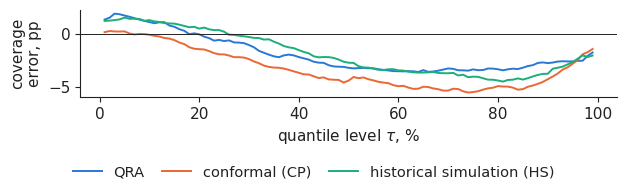

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 2.0))
for k, c, lab in [("qra", PAL["RO"], "QRA"), ("cp", PAL["DE_LU"], "conformal (CP)"), ("hs", PAL["HU"], "historical simulation (HS)")]:
    ax.plot(TAUS * 100, (np.array(PROB[k]["rel"]) - TAUS) * 100, color=c, label=lab)
ax.axhline(0, color="#222222", lw=0.7)
ax.set_xlabel("quantile level $\\tau$, %")
ax.set_ylabel("coverage\nerror, pp")
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.15, 1, 1))
plt.savefig('prob_rel.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [10]:
print("Numbers on the slide")
print(f'  Kupiec statistic, QRA: {PROB["qra"]["kupiec"]:.2f}')
print(f'  coverage of the 90% interval, QRA, %: {PROB["qra"]["c90"]:.2f}')
print(f'  coverage of the 50% interval, QRA, %: {PROB["qra"]["c50"]:.2f}')
print(f'  mean width of the 90% interval, QRA: {PROB["qra"]["w90"]:.2f}')
print(f'  average pinball loss, QRA: {PROB["qra"]["aps"]:.2f}')
print(f'  Kupiec statistic, CP: {PROB["cp"]["kupiec"]:.2f}')
print(f'  coverage of the 90% interval, CP, %: {PROB["cp"]["c90"]:.2f}')
print(f'  coverage of the 50% interval, CP, %: {PROB["cp"]["c50"]:.2f}')
print(f'  mean width of the 90% interval, CP: {PROB["cp"]["w90"]:.2f}')
print(f'  average pinball loss, CP: {PROB["cp"]["aps"]:.2f}')
print(f'  Kupiec statistic, HS: {PROB["hs"]["kupiec"]:.2f}')
print(f'  coverage of the 90% interval, HS, %: {PROB["hs"]["c90"]:.2f}')
print(f'  coverage of the 50% interval, HS, %: {PROB["hs"]["c50"]:.2f}')
print(f'  mean width of the 90% interval, HS: {PROB["hs"]["w90"]:.2f}')
print(f'  average pinball loss, HS: {PROB["hs"]["aps"]:.2f}')

Numbers on the slide
  Kupiec statistic, QRA: 162.93
  coverage of the 90% interval, QRA, %: 85.67
  coverage of the 50% interval, QRA, %: 47.33
  mean width of the 90% interval, QRA: 93.03
  average pinball loss, QRA: 8.33
  Kupiec statistic, CP: 83.33
  coverage of the 90% interval, CP, %: 86.95
  coverage of the 50% interval, CP, %: 46.45
  mean width of the 90% interval, CP: 87.57
  average pinball loss, CP: 8.47
  Kupiec statistic, HS: 154.05
  coverage of the 90% interval, HS, %: 85.80
  coverage of the 50% interval, HS, %: 45.76
  mean width of the 90% interval, HS: 86.86
  average pinball loss, HS: 8.41
